# Part 4: Power analysis
**Lab:** In God we trust, everyone else bring the data · **Analyst:** Ayhan Demir · **Notebook 4 of 5**

**Question for the CMO:** do we have enough days of data to trust a "no difference"?
**Reads:** `marketing_data.csv`, `results_cpa_ttest.csv` · **Writes:** `power_analysis_cpa.png`, `power_analysis_cpa.csv`, `power_min_days.csv`


### Setup 
- Loads the libraries used in this lab: pandas/numpy for tables, matplotlib/seaborn for charts, `scipy.stats` for the tests.
- `rng` is the fixed random "dice" (seed 42), so simulations and bootstraps give the same numbers every run.
- `OUT` is the `outputs/` folder where every chart, CSV and the memo are saved. `ALPHA = 0.05` is the significance line.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Load the data
- `N_DAYS` = the days of data we have per channel (91), which plays the role of "current data (90 days)" in the PDF.
- `BASE_CPA` = the **median of the channels' average daily CPA** (the template's example: the median CPA of the paid channels).

In [2]:
df = pd.read_csv(OUT / "marketing_data.csv", parse_dates=["date"])
df["CPA"] = (df.cost / df.conversions).replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]
cpa_res = pd.read_csv(OUT / "results_cpa_ttest.csv")

N_DAYS = df.date.nunique()
print("Days of data per channel:", N_DAYS)
print("Average daily CPA per channel:\n", paid.groupby("channel").CPA.mean().round(3).to_string())

Days of data per channel: 91
Average daily CPA per channel:
 channel
abc    0.257
def    0.510
ghi    0.416
jkl    0.405
mno    0.381


## Step 7: Do we have enough data?
**Power** = the chance of catching a difference that is **really** there (§5). We simulate many experiments where we **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- low values are capped at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

**What & why**
- Same idea as `empirical_power` in §5, but built the fast way from the speed hint: all 1,000 experiments are drawn at once as a `(n_sim, n_days)` table, and `ttest_ind(..., axis=1)` tests every row in one call.
- We already know B really is different, so **power = the share of experiments where the test says "significant"**. The target is 80%.

BASE_CPA = $0.405

Power by effect size (rows) and days of data (columns):
n_days            30    60   90    120   180
effect_size_pct                             
5                0.24  0.47  0.6  0.72  0.89
10               0.70  0.95  1.0  1.00  1.00
15               0.97  1.00  1.0  1.00  1.00
20               1.00  1.00  1.0  1.00  1.00


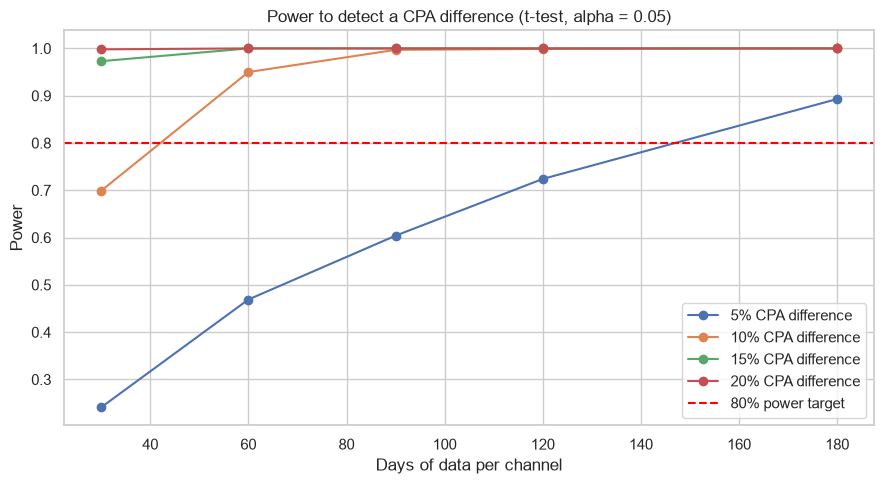

In [3]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    std = 0.15 * base_cpa
    a = rng.normal(base_cpa, std, (n_sim, n_days))                          # channel A: n_sim experiments x n_days
    b = rng.normal(base_cpa * (1 + true_diff_pct), std, (n_sim, n_days))    # channel B: truly different
    a = np.maximum(a, 0.5 * base_cpa)                                       # cap low values at 50% of base
    b = np.maximum(b, 0.5 * base_cpa)
    p = stats.ttest_ind(a, b, axis=1).pvalue                                # one t-test per experiment
    return np.mean(p < alpha)                                               # share that caught the difference

BASE_CPA = paid.groupby("channel").CPA.mean().median()     # median of the channels' average daily CPA
print(f"BASE_CPA = ${BASE_CPA:.3f}")
effects = [0.05, 0.10, 0.15, 0.20]
days = [30, 60, 90, 120, 180]

# DataFrame with columns effect_size_pct, n_days, power
rows = []
for eff in effects:
    for n in days:
        rows.append({"effect_size_pct": int(eff * 100), "n_days": n,
                     "power": empirical_power_cpa(eff, BASE_CPA, n)})
power_df = pd.DataFrame(rows)
print("\nPower by effect size (rows) and days of data (columns):")
print(power_df.pivot(index="effect_size_pct", columns="n_days", values="power").round(2).to_string())

# One line per effect size, red dashed line at 0.8
plt.figure(figsize=(9, 5))
for eff, grp in power_df.groupby("effect_size_pct"):
    plt.plot(grp.n_days, grp.power, marker="o", label=f"{eff}% CPA difference")
plt.axhline(0.8, color="red", linestyle="--", label="80% power target")
plt.xlabel("Days of data per channel")
plt.ylabel("Power")
plt.title("Power to detect a CPA difference (t-test, alpha = 0.05)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUT / "power_analysis_cpa.png", dpi=120)
plt.show()

**Minimum days for 80% power, and the check on our real pairs**
- `min_days_80` tries 5, 10, 15 … 400 days and returns the first that reaches 80% power.
- **For each CPA pair that is significant after BH:** the observed gap in %, with the **smaller mean as baseline**, its power with our 91 days, and the days needed if power < 0.8.
- **Non-significant pairs** are printed the same way. Low power there means **"not enough data"**, not **"no difference"** (the ✍️ question 3).

In [4]:
def min_days_80(true_diff_pct, base_cpa, target=0.8):
    for n in range(5, 401, 5):                      # try 5, 10, 15 ... 400 days
        if empirical_power_cpa(true_diff_pct, base_cpa, n) >= target:
            return n
    return None                                     # more than 400 days needed

# Minimum days for 80% power, per effect size: is our data enough?
min_days = pd.DataFrame({"effect_size_pct": [int(e * 100) for e in effects],
                         "min_days_for_80pct": [min_days_80(e, BASE_CPA) for e in effects]})
min_days["status_with_our_data"] = np.where(min_days.min_days_for_80pct <= N_DAYS, "sufficient", "insufficient")
print(f"With {N_DAYS} days of data per channel:")
print(min_days.to_string(index=False))

# Each CPA pair: observed % difference (smaller mean = baseline), power with our days, days needed for 80%
def pair_power(res):
    rows = []
    for r in res.itertuples():
        base = min(r.mean_a, r.mean_b)                          # smaller mean = baseline
        obs = abs(r.mean_b - r.mean_a) / base                   # observed difference as a share
        pw = empirical_power_cpa(obs, base, N_DAYS)
        rows.append({"pair": f"{r.group_a} vs {r.group_b}", "observed_diff_pct": round(obs * 100, 1),
                     "power_with_our_days": pw,
                     "days_needed_for_80pct": "enough" if pw >= 0.8 else (min_days_80(obs, base) or ">400")})
    return pd.DataFrame(rows)

print("\nCPA pairs significant after BH:")
print(pair_power(cpa_res[cpa_res.significant_fdr]).to_string(index=False))
print("\nCPA pairs NOT significant after BH:")
print(pair_power(cpa_res[~cpa_res.significant_fdr]).to_string(index=False))

With 91 days of data per channel:
 effect_size_pct  min_days_for_80pct status_with_our_data
               5                 145         insufficient
              10                  40           sufficient
              15                  20           sufficient
              20                  15           sufficient

CPA pairs significant after BH:
      pair  observed_diff_pct  power_with_our_days days_needed_for_80pct
abc vs def               98.6                  1.0                enough
abc vs ghi               62.1                  1.0                enough
abc vs jkl               57.8                  1.0                enough
abc vs mno               48.3                  1.0                enough
def vs ghi               22.6                  1.0                enough
def vs jkl               25.9                  1.0                enough
def vs mno               33.9                  1.0                enough

CPA pairs NOT significant after BH:
      pair  observed_d

**✍️ Answer:**
1. **What size of CPA difference can the data detect reliably?** With 91 days per channel and the lab's model (daily spread = 15% of the mean CPA), **10% or more**. That gives power of 1.0 at 90 days, and a 10% gap needs only about 40 days. A **5%** gap reaches only about 0.6 power.
2. **Days needed for a 5% difference:** about **145 days per channel** for 80% power. This matches the rule that half the gap (10% → 5%) needs about 4× the data (40 → about 145 days).
3. **Non-significant pairs: "not enough data", not "no difference".**
   - The non-significant pairs are ghi vs jkl (2.7%), ghi vs mno (9.3%) and jkl vs mno (6.4%). On paper, 91 days should be enough for the 6% to 9% gaps (power 0.82 to 0.98), so why weren't they significant?
   - Because the model assumes a 15% day-to-day spread, while the real daily CPA spread is **45% to 63%** of the mean (CV in notebook 01). That is 3 to 4 times larger, and the days needed grow with the **square** of the spread (about 11× more).
   - In reality, these gaps would need hundreds to thousands of days to show up. So they mean **not enough data**, not proof that the channels are equal.
   - The significant pairs all have big gaps (23% to 99%), so they hold even with the real spread. One caveat: the pairs with `abc` rest on only 22 CPA days, not 91.


### Save the power tables for notebook 05

In [5]:
power_df.to_csv(OUT / "power_analysis_cpa.csv", index=False)
min_days.to_csv(OUT / "power_min_days.csv", index=False)
print("Saved power tables")

Saved power tables
